In [1]:
%load_ext pyspecdata.ipy
from itertools import cycle
import matplotlib.pyplot as plt
import numpy as np

First, we load our files, and just see what the data looks like

In [2]:
d1 = find_file("240612_TS_C10_W20_11mM_run1.DSC", exp_type="francklab_esr/romana") # cooling 1 --initial sample
d2 = find_file("240612_TS_C10_W20_11mM_run2.DSC", exp_type="francklab_esr/romana") # heating 1 subsequently --after cooling and heating

In [3]:
d1.shape  # this shows me what the dimensions are

[(1024, '$B_0$'), (31, 'Temperature'), (10, 'harmonic')]

In [4]:
d2.shape

[(1024, '$B_0$'), (31, 'Temperature'), (10, 'harmonic')]

In [5]:
d1.chunk_auto("harmonic", "harmonic")  # the harmonic is typically stored so that we need to do this
d1.shape  # this shows me what the dimensions are

[(1024, '$B_0$'), (31, 'Temperature'), (2, 'phase'), (5, 'harmonic')]

In [6]:
d2.chunk_auto("harmonic", "harmonic")
d2.shape

[(1024, '$B_0$'), (31, 'Temperature'), (2, 'phase'), (5, 'harmonic')]

I start by plotting as a 2D pcolor plot:

Text(0.5, 1.0, 'cooling1')

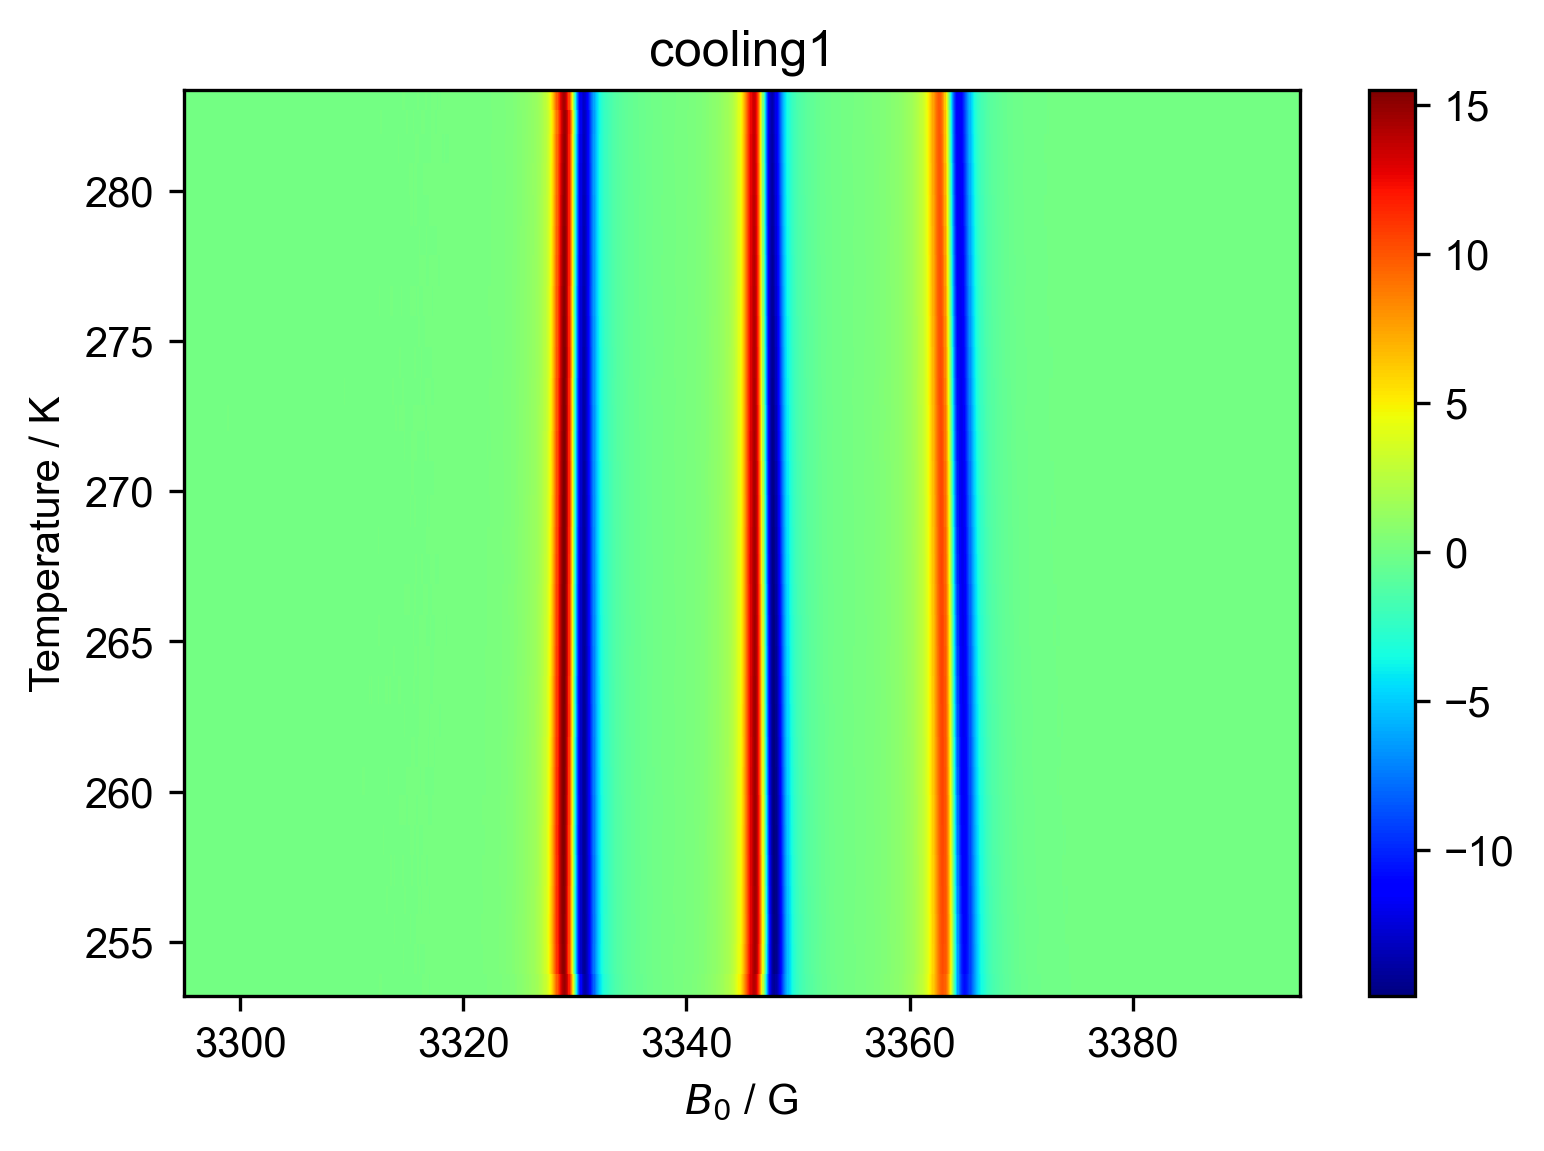

In [7]:
figure(dpi=300)
d1 = d1["harmonic", 0]["phase", 0]  # select only the "standard" EPR -- ignore the higher harmonics.  Make sure you can parse this!
d1.sort('Temperature')
d1.reorder("Temperature").pcolor()
title("cooling1")

Text(0.5, 1.0, 'heating1')

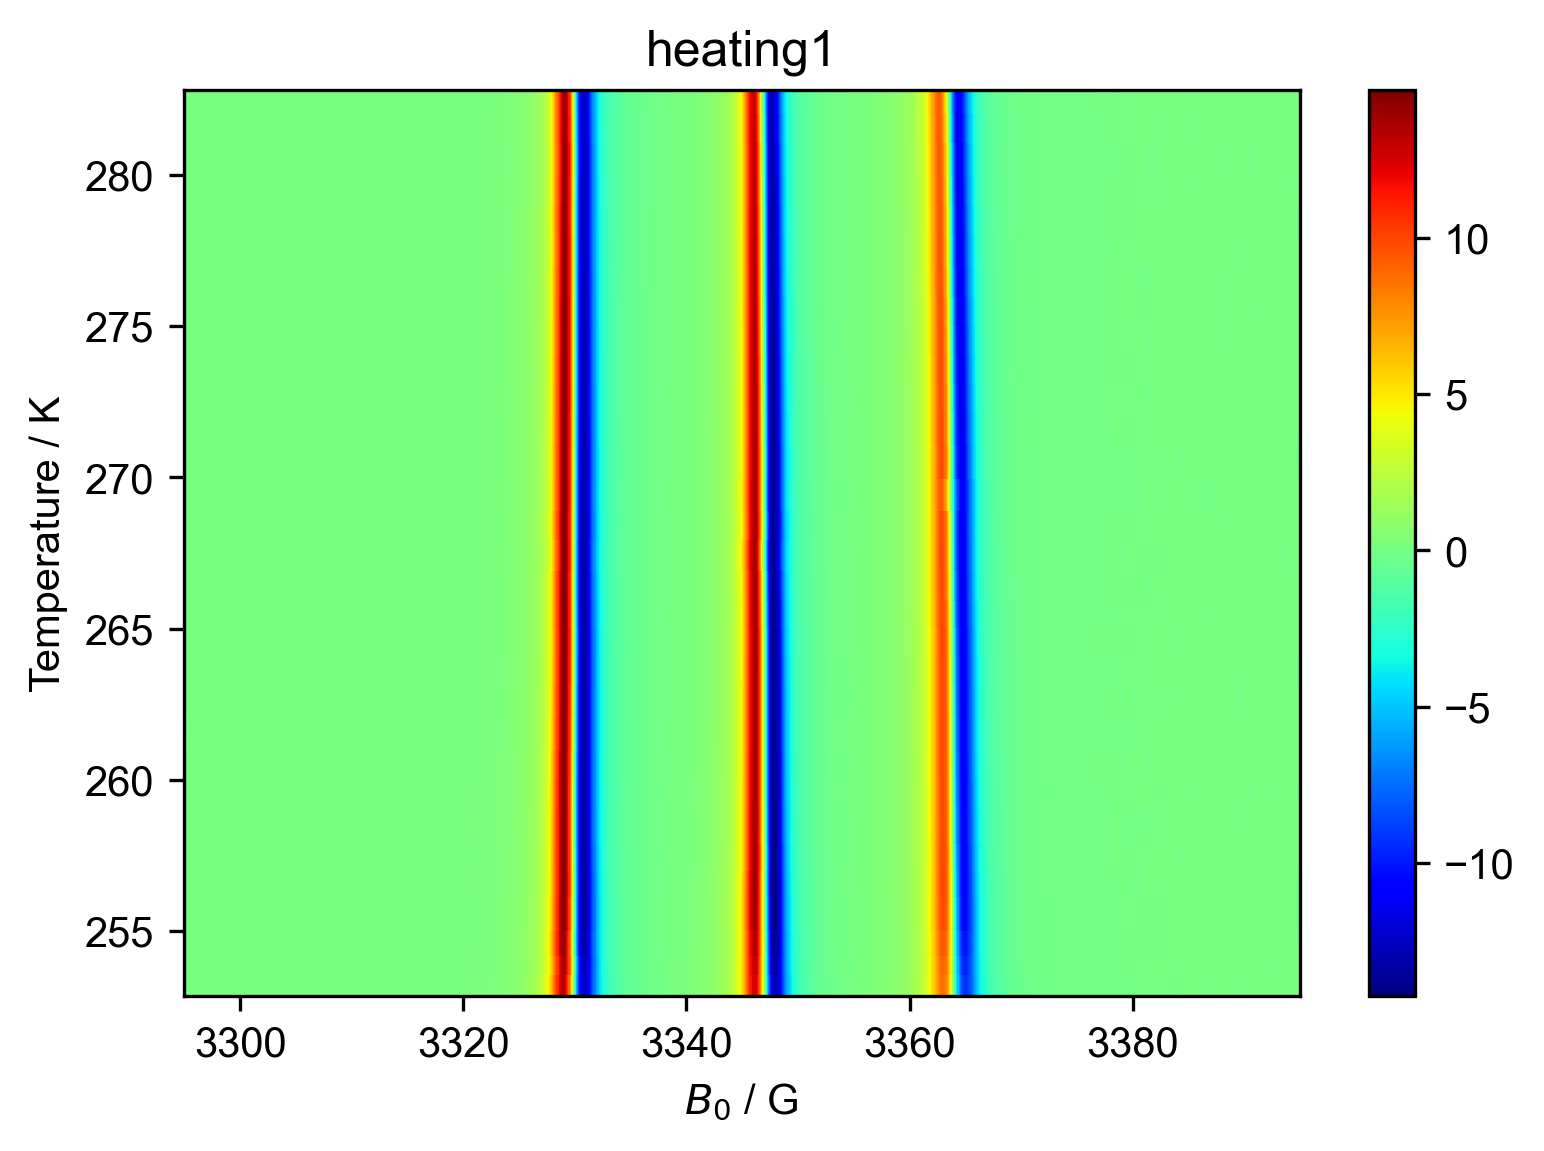

In [8]:
figure(dpi=300)
d2 = d2["harmonic", 0]["phase", 0]
d2.sort('Temperature')
d2.reorder("Temperature").pcolor()
title("heating1")

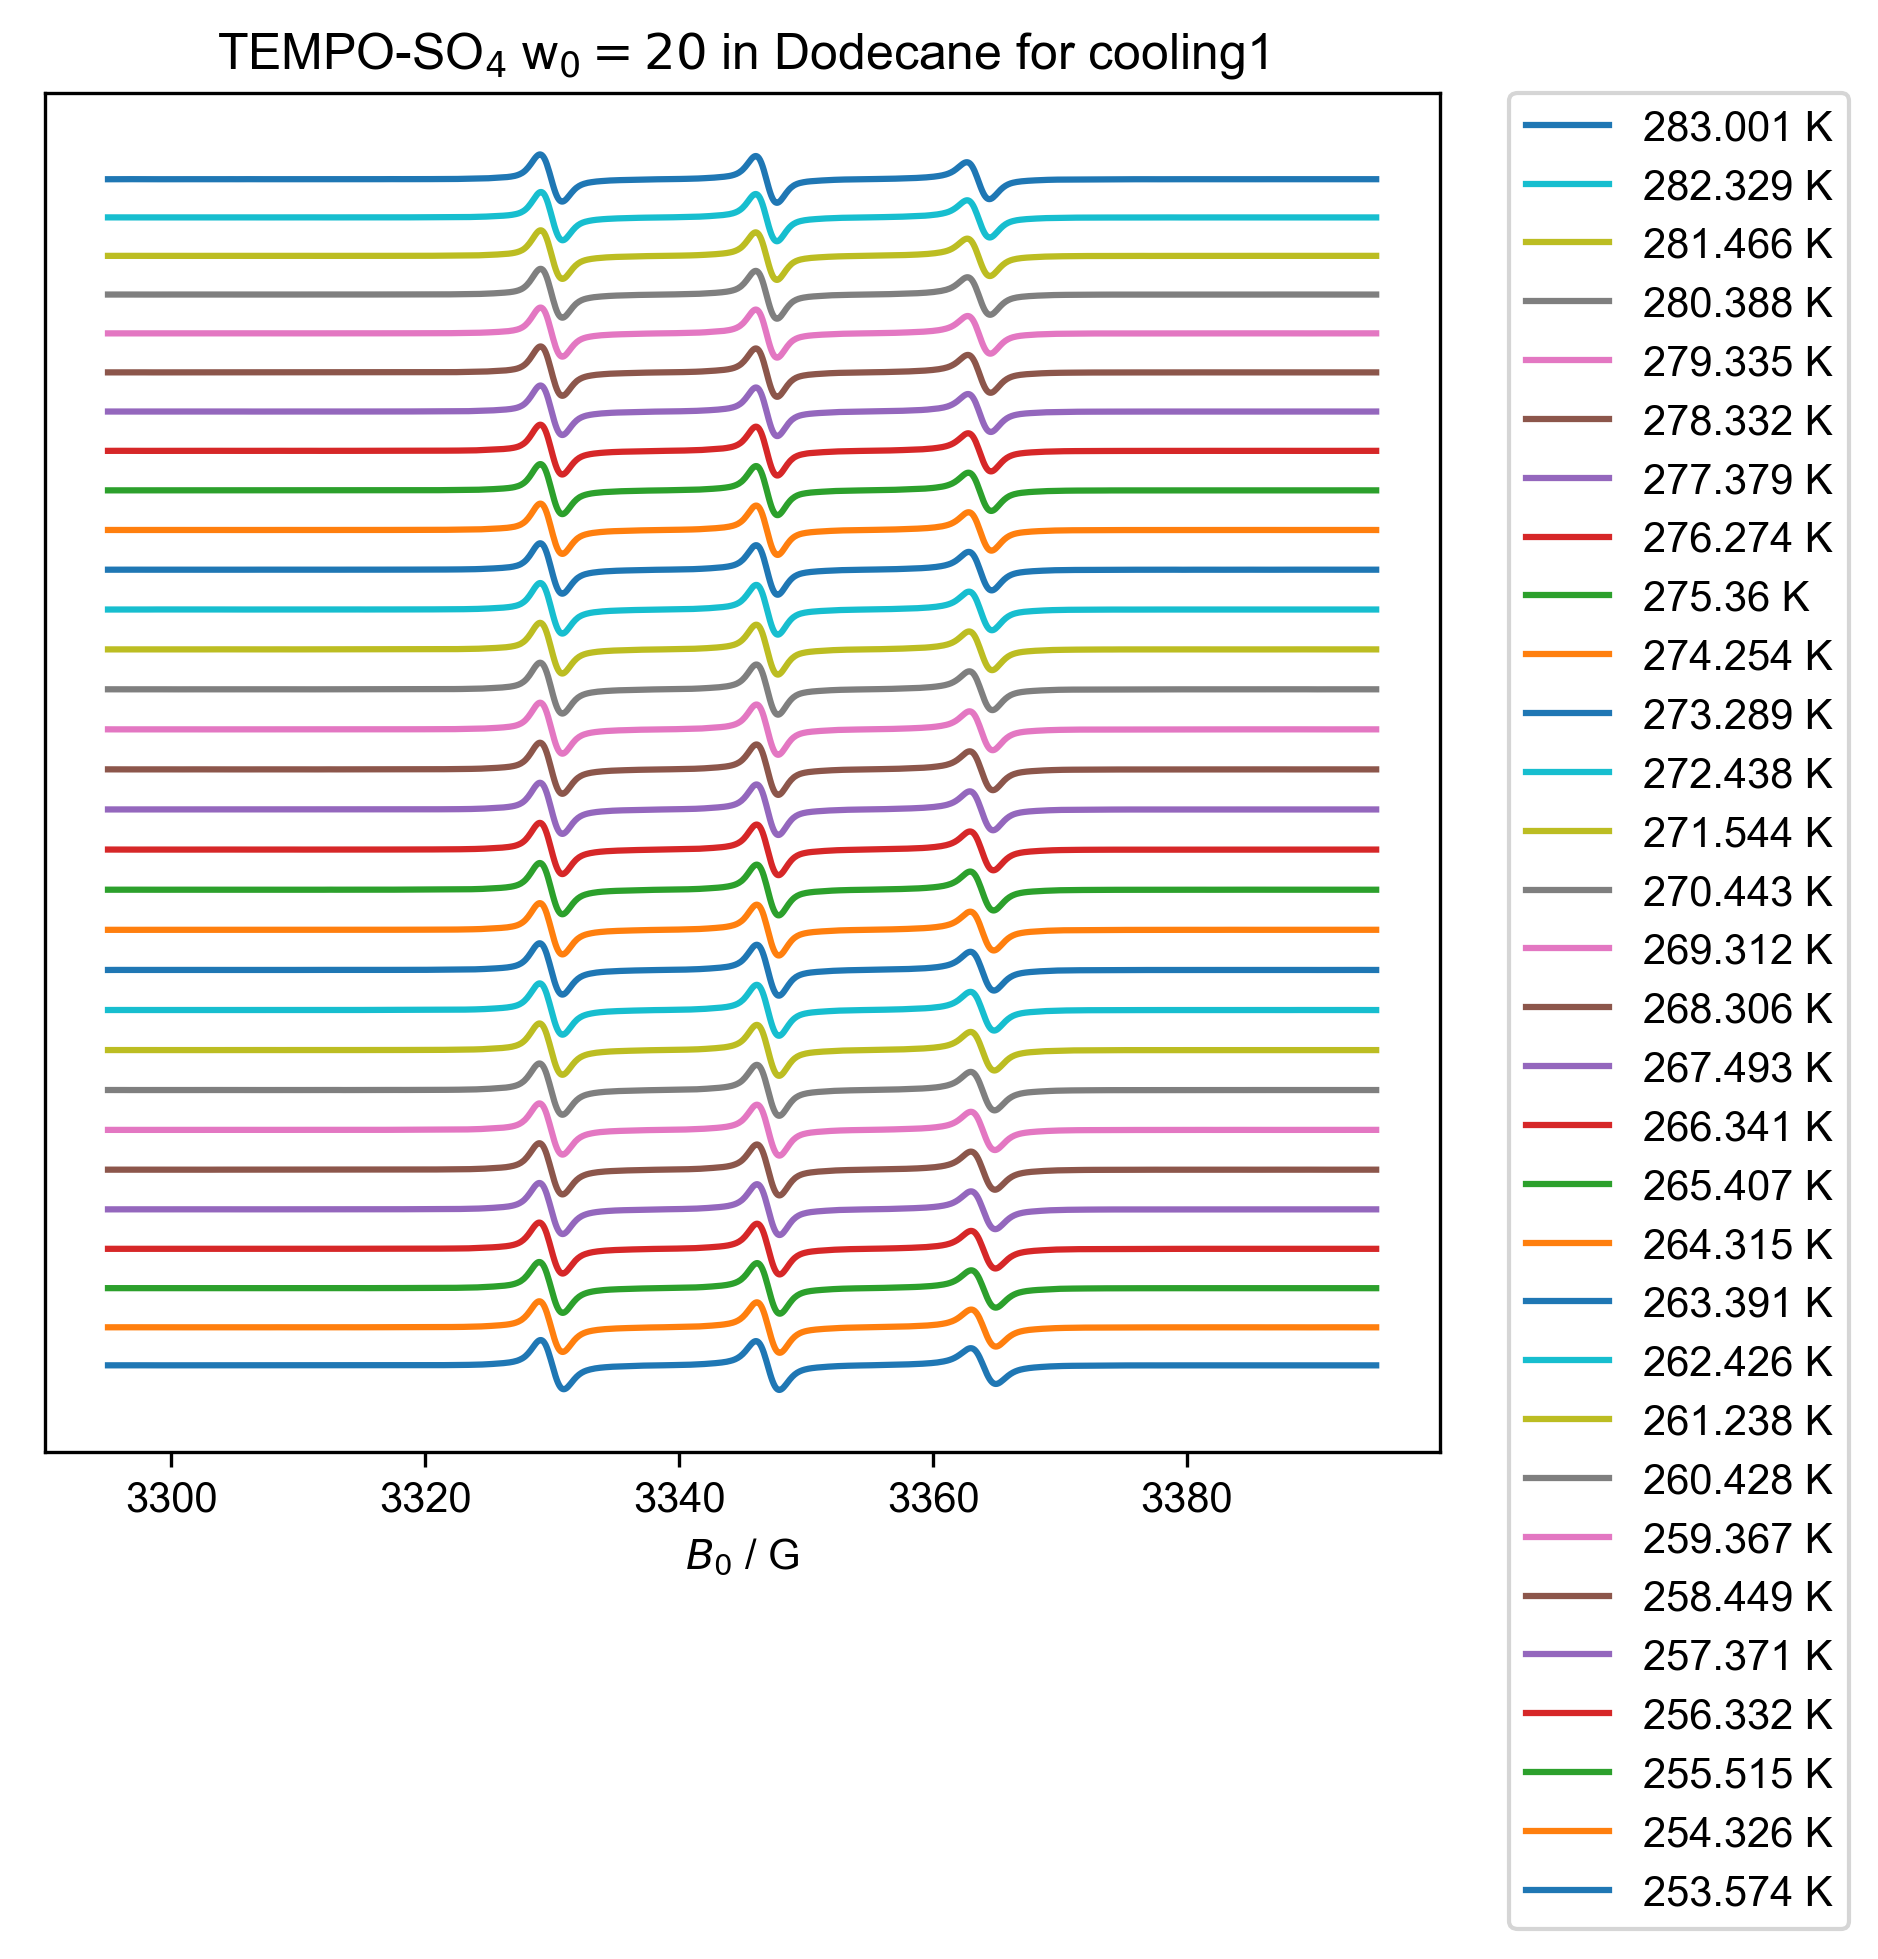

In [9]:
#cooling same plot in offset
offset= 0

for this_label, temp_range in [
    ("TEMPO-SO$_4$ w$_0= 20$ in Dodecane for cooling1", (200, 300))
]:
    this_d1 = d1["Temperature":temp_range]
    figure(dpi=300, figsize=(6,6)) # this is standard matplotlib to open a new figure
    title(this_label)
    for temp_ithis_dx in range(this_d1.shape["Temperature"]):
        this_temp = this_d1.getaxis("Temperature")[temp_ithis_dx]
        plot(this_d1["Temperature", temp_ithis_dx] + offset, label=f"{this_temp} K")        
        offset += this_d1["Temperature", temp_ithis_dx].max()*1.5
        ax=plt.gca()
        ax.set_yticks([])
        ax.set_ylabel(None)
        handles, labels = plt.gca().get_legend_handles_labels()
        handles.reverse()
        labels.reverse()
        legend(handles, labels, bbox_to_anchor=(1.05, 1), loc=2, borderaxespad=0.)

#     fancy_legend()

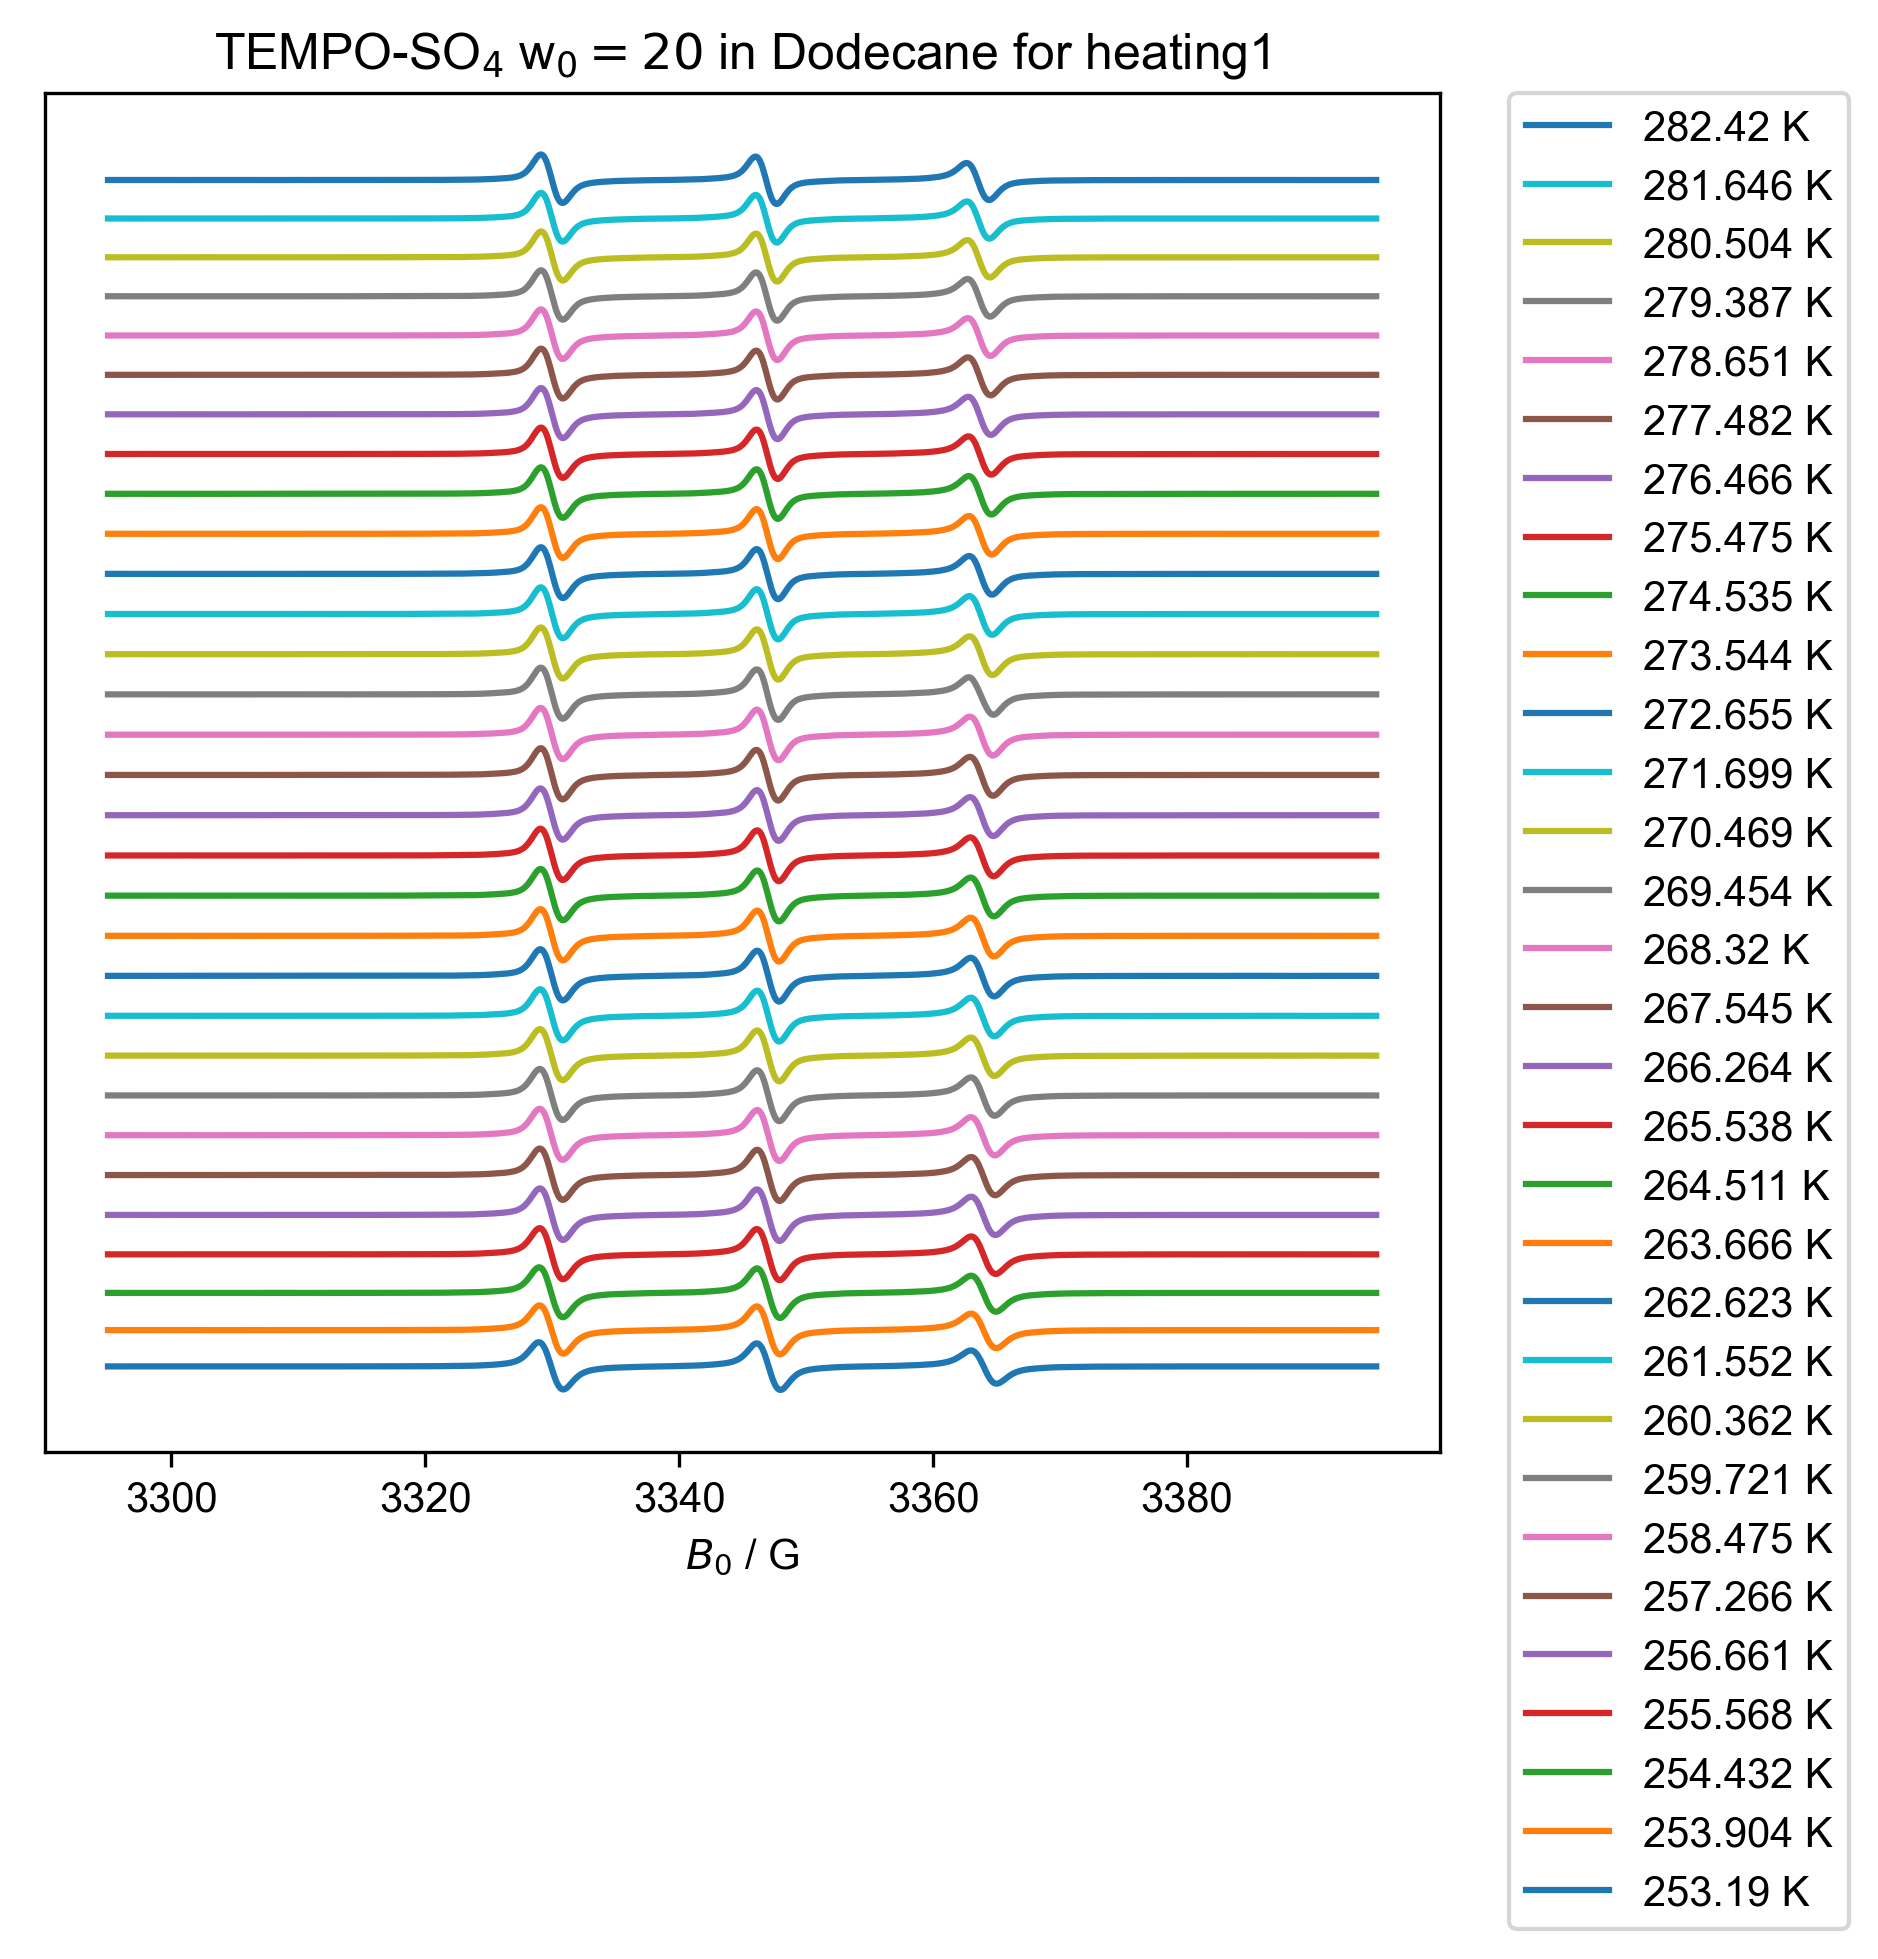

In [10]:
#heating run2 in same plot
offset =0

for this_label, temp_range in [
    ("TEMPO-SO$_4$ w$_0=20$ in Dodecane for heating1", (173, 373)),
]:
    this_d2 = d2["Temperature":temp_range]
    figure(dpi=300, figsize=(6,6)) # this is standard matplotlib to open a new figure
    title(this_label)
    for temp_ithis_dx in range(this_d2.shape["Temperature"]):
        this_temp = this_d2.getaxis("Temperature")[temp_ithis_dx]
        plot(this_d2["Temperature", temp_ithis_dx] + offset, label=f"{this_temp} K")
        offset += this_d2["Temperature", temp_ithis_dx].max()*1.5
        ax=plt.gca()
        ax.set_yticks([])
        ax.set_ylabel(None)
        handles, labels = plt.gca().get_legend_handles_labels()
        handles.reverse()
        labels.reverse()
        legend(handles, labels, bbox_to_anchor=(1.05, 1), loc=2, borderaxespad=0.)

#     fancy_legend()

[253.574 254.326 255.515 256.332 257.371 258.449 259.367 260.428 261.238
 262.426 263.391 264.315 265.407 266.341 267.493 268.306 269.312 270.443
 271.544 272.438 273.289 274.254 275.36  276.274 277.379 278.332 279.335
 280.388 281.466 282.329 283.001]
[253.19  253.904 254.432 255.568 256.661 257.266 258.475 259.721 260.362
 261.552 262.623 263.666 264.511 265.538 266.264 267.545 268.32  269.454
 270.469 271.699 272.655 273.544 274.535 275.475 276.466 277.482 278.651
 279.387 280.504 281.646 282.42 ]


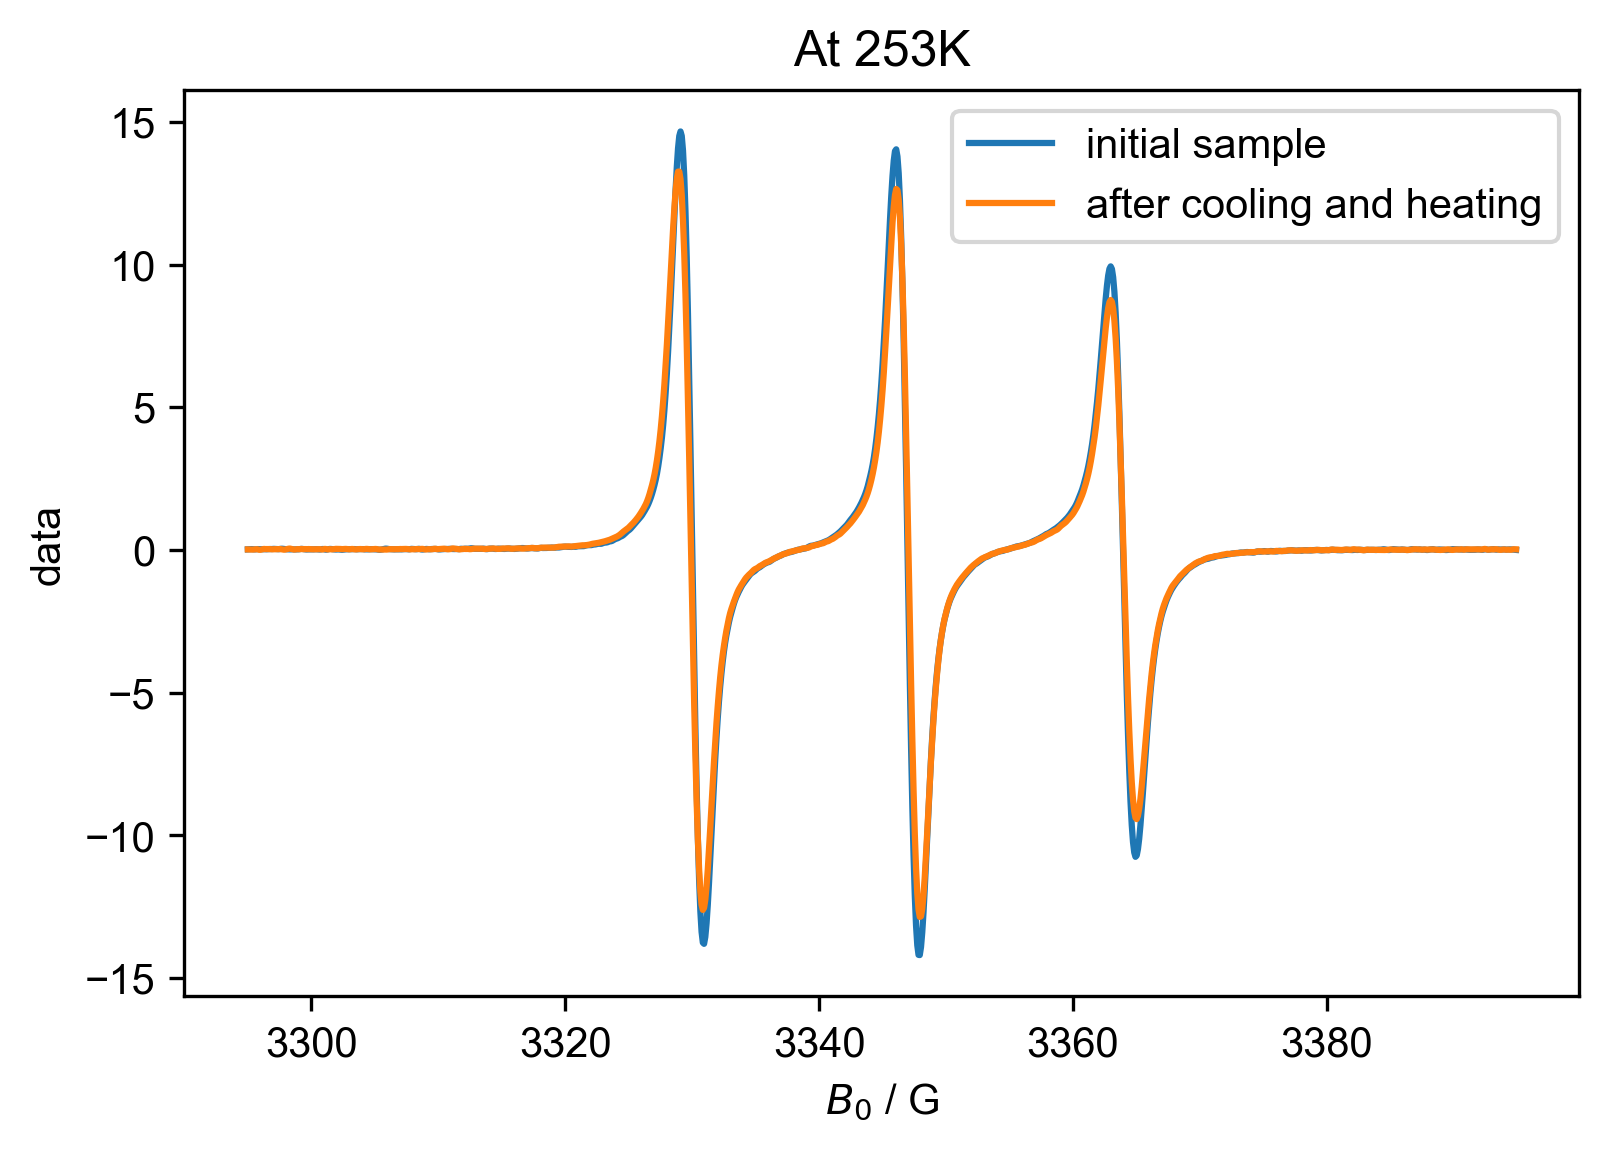

In [11]:
#near room temperature
print(d1.getaxis("Temperature"))
print(d2.getaxis("Temperature"))
figure(dpi=300, figsize=(6,4))
plot(d1["Temperature":253], label="initial sample")
plot(d2["Temperature":253], label="after cooling and heating")
title("At 253K")
legend()

[253.574 254.326 255.515 256.332 257.371 258.449 259.367 260.428 261.238
 262.426 263.391 264.315 265.407 266.341 267.493 268.306 269.312 270.443
 271.544 272.438 273.289 274.254 275.36  276.274 277.379 278.332 279.335
 280.388 281.466 282.329 283.001]
[253.19  253.904 254.432 255.568 256.661 257.266 258.475 259.721 260.362
 261.552 262.623 263.666 264.511 265.538 266.264 267.545 268.32  269.454
 270.469 271.699 272.655 273.544 274.535 275.475 276.466 277.482 278.651
 279.387 280.504 281.646 282.42 ]


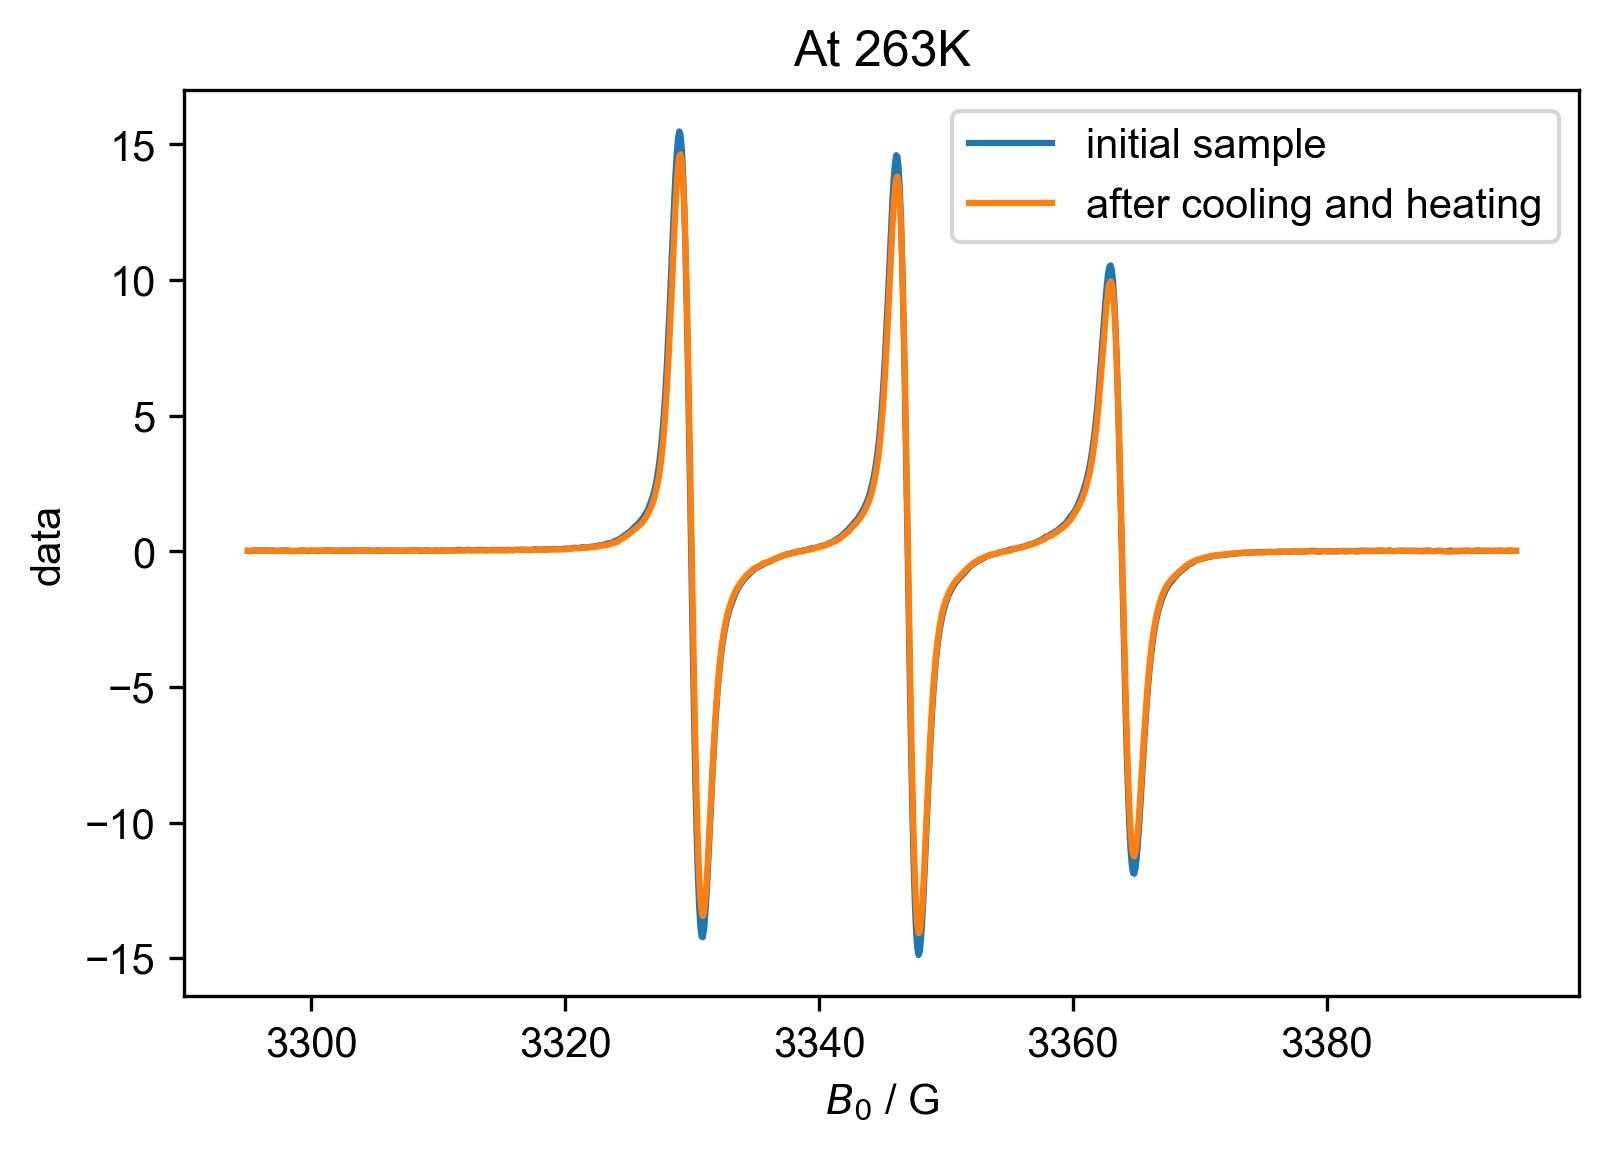

In [12]:
#near room temperature
print(d1.getaxis("Temperature"))
print(d2.getaxis("Temperature"))
figure(dpi=300, figsize=(6,4))
plot(d1["Temperature":263], label="initial sample")
plot(d2["Temperature":263], label="after cooling and heating")
title("At 263K")
legend()

[253.574 254.326 255.515 256.332 257.371 258.449 259.367 260.428 261.238
 262.426 263.391 264.315 265.407 266.341 267.493 268.306 269.312 270.443
 271.544 272.438 273.289 274.254 275.36  276.274 277.379 278.332 279.335
 280.388 281.466 282.329 283.001]
[253.19  253.904 254.432 255.568 256.661 257.266 258.475 259.721 260.362
 261.552 262.623 263.666 264.511 265.538 266.264 267.545 268.32  269.454
 270.469 271.699 272.655 273.544 274.535 275.475 276.466 277.482 278.651
 279.387 280.504 281.646 282.42 ]


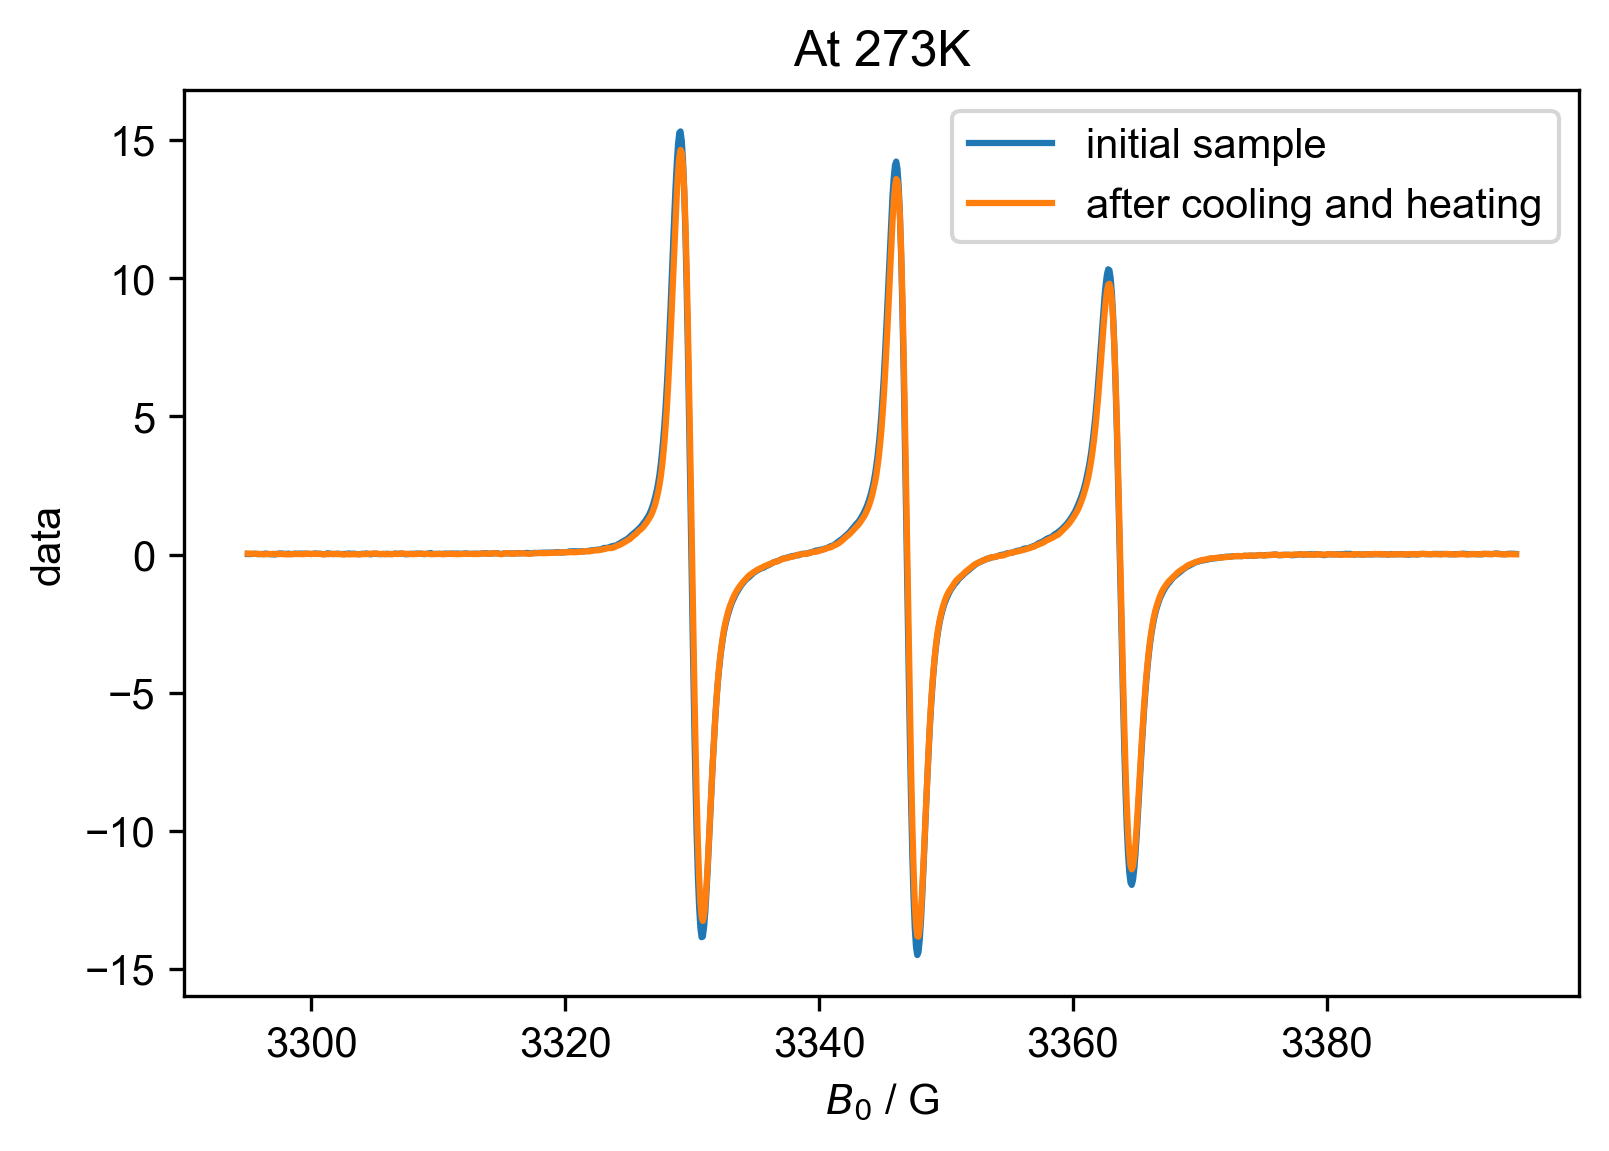

In [13]:
#near room temperature
print(d1.getaxis("Temperature"))
print(d2.getaxis("Temperature"))
figure(dpi=300, figsize=(6,4))
plot(d1["Temperature":273], label="initial sample")
plot(d2["Temperature":273], label="after cooling and heating")
title("At 273K")
legend()

[253.574 254.326 255.515 256.332 257.371 258.449 259.367 260.428 261.238
 262.426 263.391 264.315 265.407 266.341 267.493 268.306 269.312 270.443
 271.544 272.438 273.289 274.254 275.36  276.274 277.379 278.332 279.335
 280.388 281.466 282.329 283.001]
[253.19  253.904 254.432 255.568 256.661 257.266 258.475 259.721 260.362
 261.552 262.623 263.666 264.511 265.538 266.264 267.545 268.32  269.454
 270.469 271.699 272.655 273.544 274.535 275.475 276.466 277.482 278.651
 279.387 280.504 281.646 282.42 ]


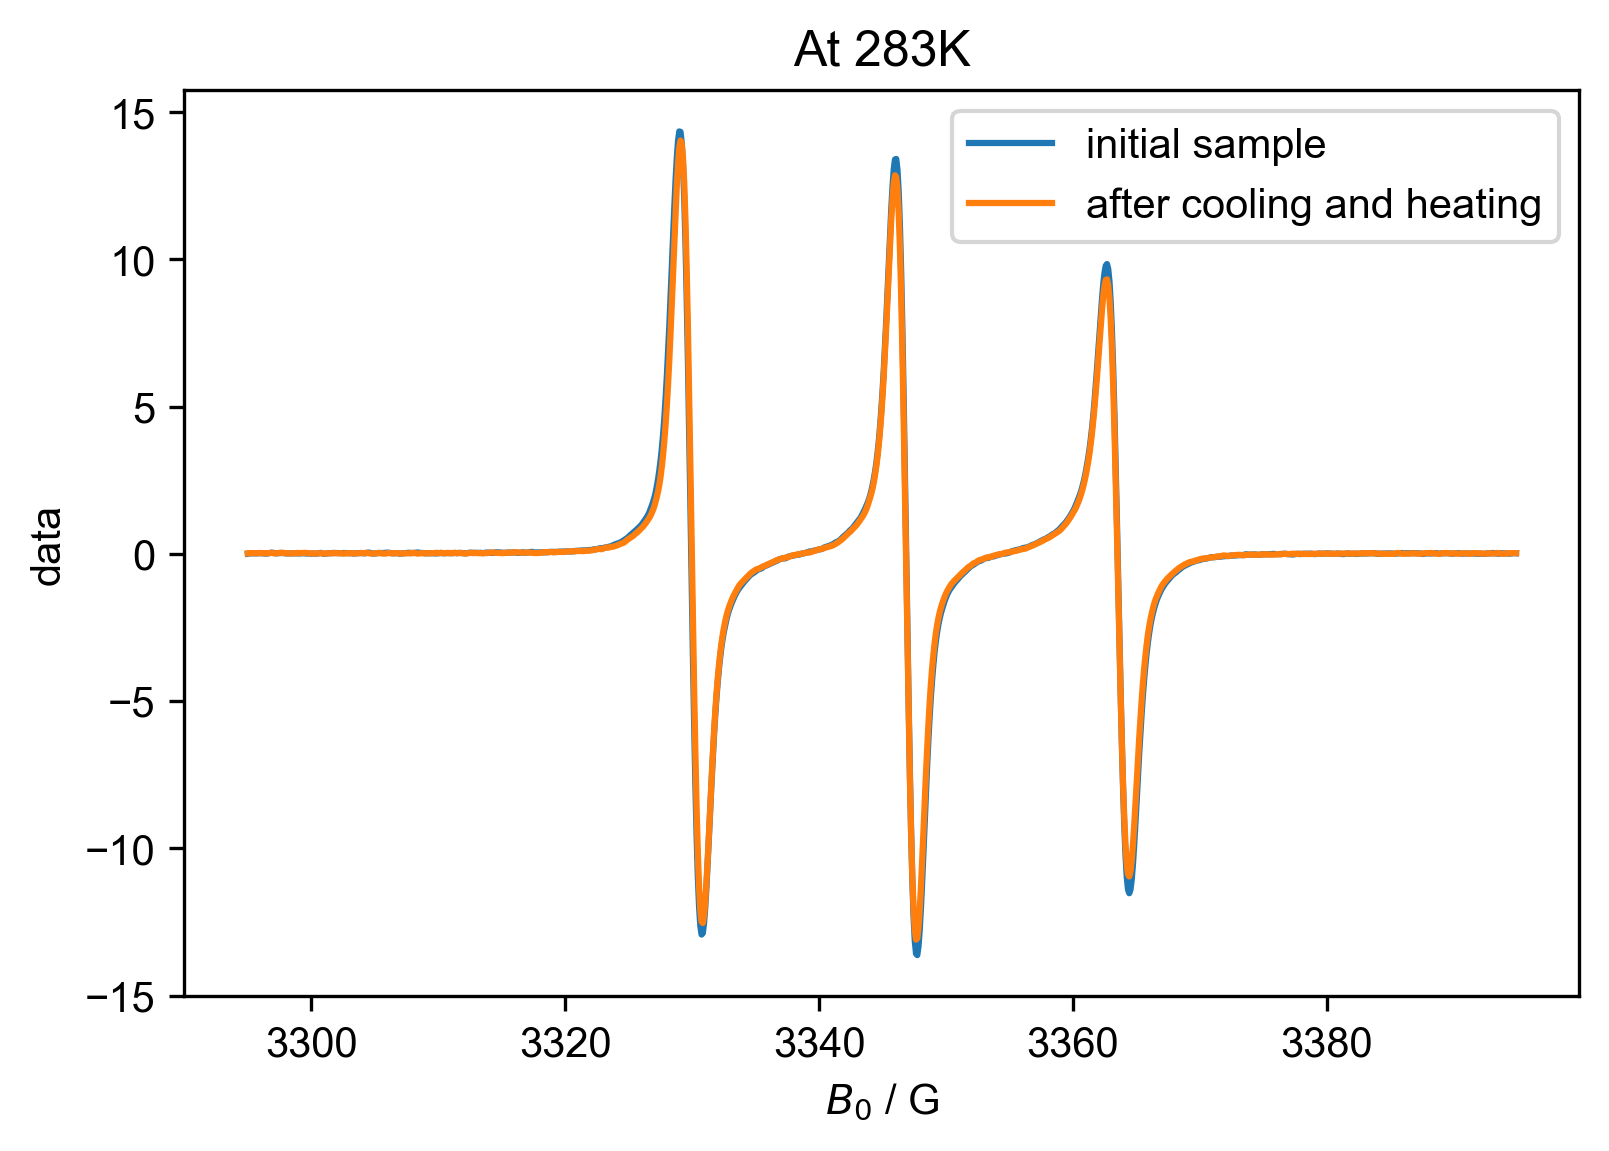

In [14]:
#near room temperature
print(d1.getaxis("Temperature"))
print(d2.getaxis("Temperature"))
figure(dpi=300, figsize=(6,4))
plot(d1["Temperature":283], label="initial sample")
plot(d2["Temperature":283], label="after cooling and heating")
title("At 283K")
legend()

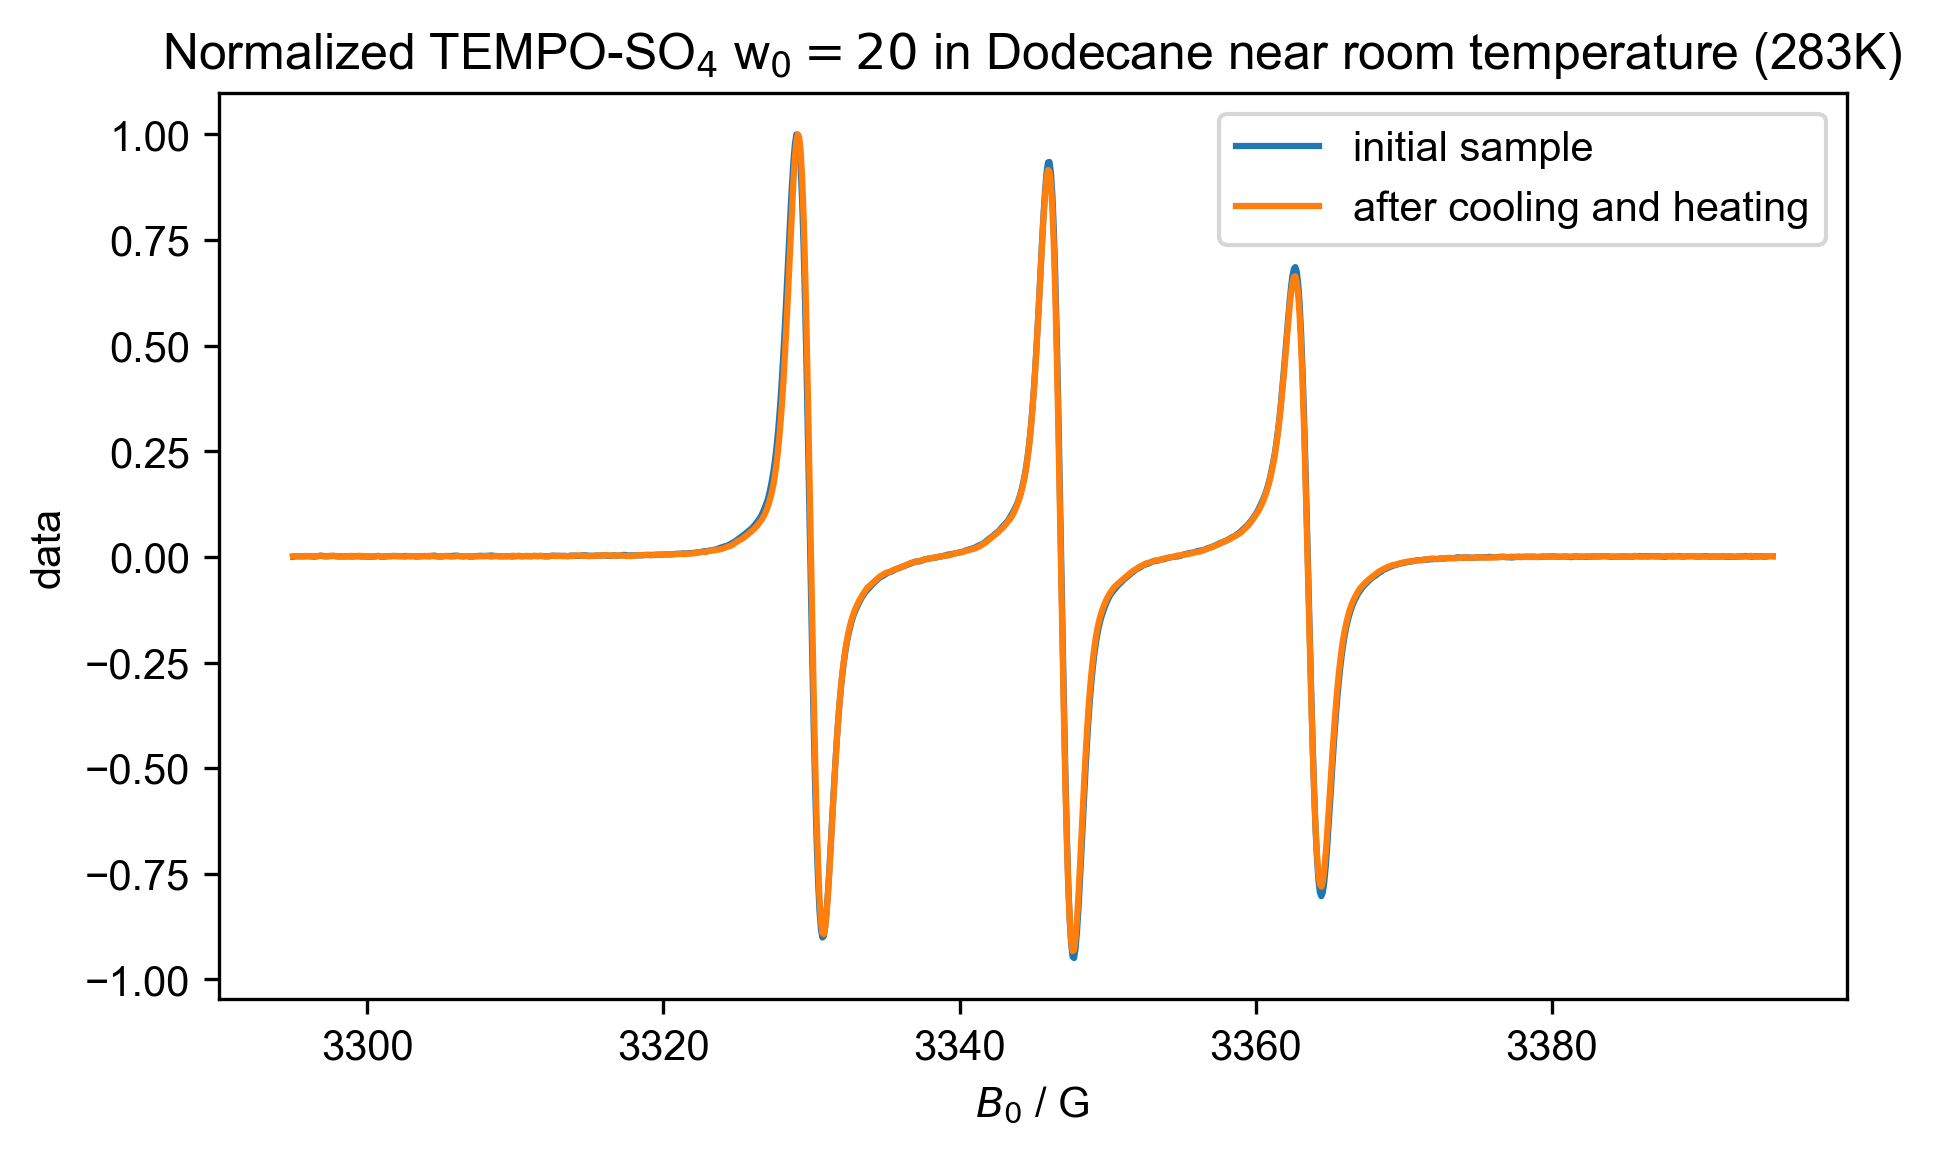

In [15]:
# #Normalized
# figure(dpi=300, figsize=(7,4))
# plot(d1["Temperature": 283] / d1["Temperature": 283].max(), label= "initial sample")
# plot(d2["Temperature": 283] / d2["Temperature": 283].max(), label= "after cooling and heating")
# title("Normalized TEMPO-SO$_4$ w$_0= 20$ in Dodecane near room temperature (283K)")
# legend()